# Statistical Methods in AI (Monsoon 2026) — Assignment 3

**Question 1:** Census Income Prediction with a Random Forest implemented from scratch



**Libraries:** NumPy / pandas / matplotlib only. No scikit-learn is used anywhere in this notebook; decision tree, bootstrap, random forest, OOB, feature importances, one-hot encoding, split and all metrics are written from scratch.



* **Every** random number generator in this notebook is created from `seed` (directly, or from a child seed drawn
  from a generator that was itself created from `seed`), so re-running the notebook gives identical numbers.
* `stamp()` writes the username inside each plot, as required.

In [1]:
import hashlib
import os
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=RuntimeWarning)  # we deliberately handle 0*log(0) etc.

USERNAME = "maddhipatla.devi"   
seed = int(hashlib.sha256(USERNAME.encode()).hexdigest(), 16) % (2**32)

print("username:", USERNAME, "| seed:", seed)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")


def stamp(ax=None):
    """Write the username in the top-right corner of an axis (assignment requirement)."""
    ax = ax if ax is not None else plt.gca()
    ax.text(0.95, 0.95, USERNAME, ha="right", va="top", transform=ax.transAxes,
            fontsize=10, color="gray", alpha=0.7)


def timed(fn, *args, **kwargs):
    """Run fn(*args, **kwargs) and return (result, elapsed_seconds)."""
    t0 = time.perf_counter()
    out = fn(*args, **kwargs)
    return out, time.perf_counter() - t0


def find_file(name, extra_dirs=()):
    """Look for a data file in the usual places (current dir, ./data, parent dirs, user supplied dirs)."""
    for d in [Path("."), Path("data"), Path(".."), Path("../data"), *map(Path, extra_dirs)]:
        if (d / name).exists():
            return d / name
    return None


# =====================================================================================
# PART 1 — CENSUS INCOME PREDICTION WITH RANDOM FORESTS
# =====================================================================================

username: maddhipatla.devi | seed: 1802276234


# Question 1 — Census Income Prediction with Random Forests

## 1.1 Data Preprocessing
### 1.1.1 Dataset exploration

Loading notes (these are properties of the official UCI files):
* missing values are written as `?` → converted to `NaN`;
* `adult.test` has a junk first line (`|1x3 Cross validator`) which is skipped;
* labels in `adult.test` end with a full stop (`<=50K.`) → stripped so both files use the same two labels;
* values have a leading space (`, Private`) → `skipinitialspace=True`.

In [2]:
ADULT_COLS = ["age", "workclass", "fnlwgt", "education", "education-num", "marital-status", "occupation",
              "relationship", "race", "sex", "capital-gain", "capital-loss", "hours-per-week",
              "native-country", "income"]
NUM_COLS = ["age", "fnlwgt", "education-num", "capital-gain", "capital-loss", "hours-per-week"]
CAT_COLS = ["workclass", "education", "marital-status", "occupation", "relationship", "race", "sex",
            "native-country"]
TARGET = "income"


def read_adult(path, is_test=False):
    """Read one of the official Adult files into a DataFrame with clean strings and NaN for '?'."""
    df = pd.read_csv(path, header=None, names=ADULT_COLS, skipinitialspace=True,
                     skiprows=1 if is_test else 0, na_values="?", skip_blank_lines=True)
    df = df.dropna(how="all").reset_index(drop=True)        # drop stray empty lines at end of file
    for c in CAT_COLS + [TARGET]:
        df[c] = df[c].astype("object").where(df[c].isna(), df[c].astype(str).str.strip())
    df[TARGET] = df[TARGET].str.rstrip(".")                   # '<=50K.' -> '<=50K'
    return df


p_data, p_test = find_file("adult.data"), find_file("adult.test")
if p_data is None or p_test is None:                          # last resort: download from UCI
    import urllib.request
    base = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/"
    for fn in ["adult.data", "adult.test"]:
        urllib.request.urlretrieve(base + fn, fn)
    p_data, p_test = Path("adult.data"), Path("adult.test")

df_all = read_adult(p_data)               # 32,561 rows -> will be split into train / validation
df_test = read_adult(p_test, is_test=True)  # 16,281 rows -> final test set (touched only in 1.8)
print("files:", p_data, p_test)

files: data/adult.data data/adult.test


In [3]:
print(f"adult.data : {df_all.shape[0]} rows x {df_all.shape[1]} columns (14 features + target)")
print(f"adult.test : {df_test.shape[0]} rows x {df_test.shape[1]} columns")
print(f"adult.data + adult.test = {df_all.shape[0] + df_test.shape[0]} examples (task description: ~48,842)\n")

explore = pd.DataFrame({
    "dtype": df_all.dtypes.astype(str),
    "kind": ["numerical" if c in NUM_COLS else ("target" if c == TARGET else "categorical") for c in df_all.columns],
    "n_unique (excl. NaN)": df_all.nunique(dropna=True),
    "n_missing": df_all.isna().sum(),
    "% missing": 100 * df_all.isna().mean(),
})
display(explore)

print("\nUnique values for the categorical features:")
display(explore.loc[CAT_COLS, ["n_unique (excl. NaN)"]].T)

cls = df_all[TARGET].value_counts()
display(pd.DataFrame({"count": cls, "proportion": cls / cls.sum()}))
print("Missing values in adult.test:", df_test.isna().sum()[lambda s: s > 0].to_dict())

adult.data : 32561 rows x 15 columns (14 features + target)
adult.test : 16281 rows x 15 columns
adult.data + adult.test = 48842 examples (task description: ~48,842)



,dtype,kind,n_unique (excl. NaN),n_missing,% missing
age,int64,numerical,73,0,0.0000
workclass,object,categorical,8,1836,5.6386
fnlwgt,int64,numerical,21648,0,0.0000
education,object,categorical,16,0,0.0000
education-num,int64,numerical,16,0,0.0000
marital-status,object,categorical,7,0,0.0000
occupation,object,categorical,14,1843,5.6601
relationship,object,categorical,6,0,0.0000
race,object,categorical,5,0,0.0000
sex,object,categorical,2,0,0.0000



Unique values for the categorical features:


,workclass,education,marital-status,occupation,relationship,race,sex,native-country
n_unique (excl. NaN),8,16,7,14,6,5,2,41


,count,proportion
income,,
<=50K,24720,0.7592
>50K,7841,0.2408


Missing values in adult.test: {'workclass': 963, 'occupation': 966, 'native-country': 274}


**Missing-value strategy (decision).**
Only three categorical columns contain missing values: `workclass`, `occupation`, `native-country`
(all other columns are complete). Strategy: **replace missing values with the training-set mode** (most frequent
category) of that column. For numerical columns the code would use the training-set median (none are missing here,
so this is only defensive).

Why: (i) it is simple and keeps every row (dropping rows with `?` would remove ≈7% of the data and
bias the sample); (ii) the statistic is computed on the training split only, so no information flows from the
validation/test sets (assignment requirement); (iii) the same stored value is re-used for validation and test.
The trade-off is that the imputed rows are indistinguishable from real "Private"/"United-States" rows; an alternative
would be an explicit "Missing" category, which needs no statistics but is not what the task asks for.

### 1.1.2 Redundant features

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
age,1.0000,-0.0766,0.0365,0.0777,0.0578,0.0688
fnlwgt,-0.0766,1.0000,-0.0432,0.0004,-0.0103,-0.0188
education-num,0.0365,-0.0432,1.0000,0.1226,0.0799,0.1481
capital-gain,0.0777,0.0004,0.1226,1.0000,-0.0316,0.0784
capital-loss,0.0578,-0.0103,0.0799,-0.0316,1.0000,0.0543
hours-per-week,0.0688,-0.0188,0.1481,0.0784,0.0543,1.0000


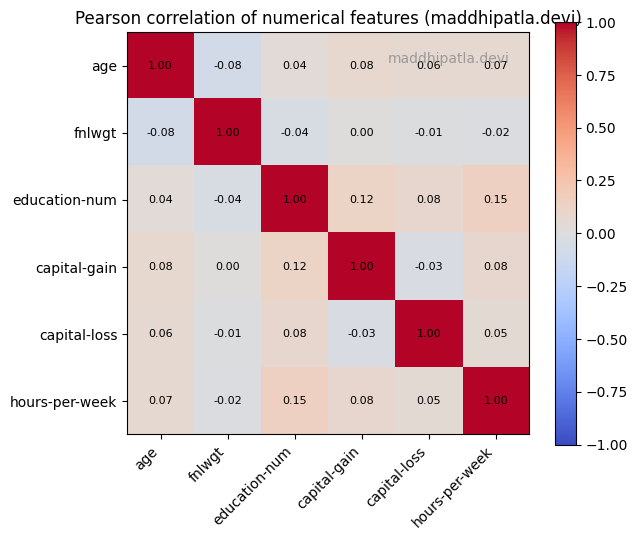

largest |correlation| between two different numerical features: 0.148
max #education-num values per education label: 1 | max #education labels per education-num value: 1


In [4]:
corr = df_all[NUM_COLS].corr(method="pearson")
display(corr)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(NUM_COLS)), NUM_COLS, rotation=45, ha="right")
ax.set_yticks(range(len(NUM_COLS)), NUM_COLS)
for i in range(len(NUM_COLS)):
    for j in range(len(NUM_COLS)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax)
ax.set_title(f"Pearson correlation of numerical features ({USERNAME})")
stamp(ax)
plt.tight_layout(); plt.show()

off_diag = corr.where(~np.eye(len(NUM_COLS), dtype=bool)).abs()
print("largest |correlation| between two different numerical features:", round(float(np.nanmax(off_diag.values)), 3))

# Education (categorical) vs education-num (numerical): is one a re-coding of the other?
n_num_per_edu = df_all.groupby("education")["education-num"].nunique().max()
n_edu_per_num = df_all.groupby("education-num")["education"].nunique().max()
print("max #education-num values per education label:", n_num_per_edu,
      "| max #education labels per education-num value:", n_edu_per_num)

**Decision.** No pair of numerical features is strongly correlated (all |r| are small, far below the usual 0.8
threshold), so no numerical feature is removed on correlation grounds. `fnlwgt` is a survey weight and is almost
uncorrelated with everything, but weak correlation is not redundancy, so it is kept.

However, the check above shows that the categorical feature `education` and the numerical feature `education-num`
are a **perfect one-to-one re-coding of each other** (1 value ↔ 1 label in both directions). `education-num` is
already ordinal, uses 1 column instead of 16 one-hot columns, and lets a tree make a single threshold split
("education-num > 12") instead of many one-hot splits. **We therefore remove `education`.**
The final feature count `p` (after one-hot encoding, section 1.1.4) is used consistently from here on.

In [5]:
DROP_COLS = ["education"]
CAT_USED = [c for c in CAT_COLS if c not in DROP_COLS]
NUM_USED = list(NUM_COLS)
print("dropped:", DROP_COLS, "| numerical kept:", NUM_USED, "| categorical kept:", CAT_USED)

dropped: ['education'] | numerical kept: ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week'] | categorical kept: ['workclass', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


### 1.1.3 Train / validation / test split
`adult.test` (official) is the final test set. `adult.data` is split 80/20, **stratified by income class**:
each class is shuffled separately with the personalised seed and 80% of *each class* goes to training. The split is
implemented from scratch (no sklearn). The test set is not touched until section 1.8.

In [6]:
def stratified_split(y, train_frac, rng):
    """Return (train_idx, val_idx): within every class, a random `train_frac` goes to train."""
    tr, va = [], []
    for c in np.unique(y):
        idx = np.where(y == c)[0]
        idx = rng.permutation(idx)
        n_tr = int(round(train_frac * len(idx)))
        tr.append(idx[:n_tr]); va.append(idx[n_tr:])
    return rng.permutation(np.concatenate(tr)), rng.permutation(np.concatenate(va))


y_all = (df_all[TARGET] == ">50K").astype(int).to_numpy()      # positive class (1) = '>50K'
y_test_full = (df_test[TARGET] == ">50K").astype(int).to_numpy()

tr_idx, va_idx = stratified_split(y_all, 0.8, np.random.default_rng(seed))
df_tr, df_va = df_all.iloc[tr_idx].reset_index(drop=True), df_all.iloc[va_idx].reset_index(drop=True)
y_tr, y_va, y_te = y_all[tr_idx], y_all[va_idx], y_test_full

split_tbl = pd.DataFrame({
    "n_samples": [len(y_tr), len(y_va), len(y_te)],
    "n (<=50K)": [(y_tr == 0).sum(), (y_va == 0).sum(), (y_te == 0).sum()],
    "n (>50K)": [(y_tr == 1).sum(), (y_va == 1).sum(), (y_te == 1).sum()],
    "% (>50K)": [100 * y_tr.mean(), 100 * y_va.mean(), 100 * y_te.mean()],
}, index=["train", "validation", "test"])
display(split_tbl)

,n_samples,n (<=50K),n (>50K),% (>50K)
train,26049,19776,6273,24.0815
validation,6512,4944,1568,24.0786
test,16281,12435,3846,23.6226


### Missing-value imputation (training statistics only)
Modes / medians are computed on `df_tr` only and then applied to train, validation and test.

In [7]:
impute_values = {}
for c in CAT_USED:
    impute_values[c] = df_tr[c].mode(dropna=True).iloc[0]       # most frequent category in TRAIN
for c in NUM_USED:
    impute_values[c] = df_tr[c].median()                         # median in TRAIN (no NaNs here anyway)
print("imputation values learned from the training split:")
print({k: v for k, v in impute_values.items() if k in ["workclass", "occupation", "native-country"]})


def impute(df):
    out = df[CAT_USED + NUM_USED].copy()
    return out.fillna(impute_values)


df_tr_i, df_va_i, df_te_i = impute(df_tr), impute(df_va), impute(df_test)
print("missing values left (train/val/test):", int(df_tr_i.isna().sum().sum()), int(df_va_i.isna().sum().sum()),
      int(df_te_i.isna().sum().sum()))

imputation values learned from the training split:
{'workclass': 'Private', 'occupation': 'Prof-specialty', 'native-country': 'United-States'}
missing values left (train/val/test): 0 0 0


### 1.1.4 One-hot encoding (categories learned from the training set only)
* `categories[c]` = sorted unique values of column `c` **in the training set**.
* The encoder is written with plain `for`-loops (no `pd.get_dummies`, no `OneHotEncoder`), as required.
* Validation/test rows are encoded with these same categories. A category that never occurs in training
  simply produces all-zero indicators for that column — nothing from validation/test can create a new column.
* Numerical columns are kept as they are (trees are invariant to monotone scaling, so no scaling is needed).


In [8]:
categories = {c: sorted(df_tr_i[c].unique()) for c in CAT_USED}
feature_names = NUM_USED + [f"{c}={v}" for c in CAT_USED for v in categories[c]]

# column offset of every (categorical column, category) pair inside the final feature matrix
offset, col_of = len(NUM_USED), {}
for c in CAT_USED:
    for v in categories[c]:
        col_of[(c, v)] = offset
        offset += 1
n_features_total = offset


def one_hot(df):
    """Vanilla for-loop one-hot encoding. Numerical columns first, then one 0/1 column per
    (categorical column, TRAINING category). Unseen categories leave all their indicators at 0."""
    n = len(df)
    X = np.zeros((n, n_features_total))
    num_vals = df[NUM_USED].to_numpy(dtype=float)
    cat_vals = {c: df[c].to_numpy() for c in CAT_USED}
    for i in range(n):                                   # loop over rows
        for j in range(len(NUM_USED)):                   # copy numerical features
            X[i, j] = num_vals[i, j]
        for c in CAT_USED:                               # loop over categorical columns
            k = col_of.get((c, cat_vals[c][i]))          # column of this row's category (None if unseen)
            if k is not None:
                X[i, k] = 1.0
    return X


X_tr, X_va, X_te = one_hot(df_tr_i), one_hot(df_va_i), one_hot(df_te_i)
p = X_tr.shape[1]
assert X_tr.shape[1] == X_va.shape[1] == X_te.shape[1] == len(feature_names)
assert (X_tr[:, len(NUM_USED):].sum(axis=1) == len(CAT_USED)).all()   # exactly one 1 per categorical column
print(f"final number of features p = {p}  ({len(NUM_USED)} numerical + {p - len(NUM_USED)} one-hot columns)")
print("X_train", X_tr.shape, "| X_val", X_va.shape, "| X_test", X_te.shape)
unseen = {c: sorted(set(df_te_i[c].unique()) - set(categories[c])) for c in CAT_USED}
print("test categories never seen in training:", {k: v for k, v in unseen.items() if v})


final number of features p = 89  (6 numerical + 83 one-hot columns)
X_train (26049, 89) | X_val (6512, 89) | X_test (16281, 89)
test categories never seen in training: {}


## 1.2 Decision tree from scratch

The code below follows the starter template (`gini_impurity`, `entropy`, `information_gain`, `TreeNode`,
`DecisionTree`) and fills in every `pass`. The starter file contained a syntax error
(`TreeNode(feature_index=, threshold=, ...)`), which is fixed here.

**Design decisions**
1. *Thresholds.* For a numerical column the candidate thresholds are the **midpoints between consecutive distinct
   sorted values**; the rule is `x <= threshold → left`. Splits that would give an empty child (or fewer than
   `min_samples_leaf` samples in a child) are rejected.
2. *Speed (same result, faster).* A naive search recomputes the impurity of both children for every threshold,
   O(n²) per feature. Instead we sort the column once, take **cumulative class counts**, and compute the impurity of
   every candidate split at once (vectorised): O(n log n) per feature. One-hot columns only have one meaningful
   threshold (0.5), so all of them are scored together with one matrix product (`X_bin.T @ Y_onehot`).
   Section 1.2.1 verifies the fast search against a brute-force search that uses the plain
   `gini_impurity` / `entropy` functions.
3. *Leaf prediction* = majority class of the training samples that reach the leaf; ties go to the smaller class
   label. The class counts are stored, so `predict_proba` returns the class fractions of the leaf.
4. *Impurity-based importance.* For every split we record `(n_node / n_train) × (impurity_parent −
   weighted impurity_children)` for the chosen feature (section 1.7.1).
5. *Prediction* flattens the tree into arrays and moves all samples down the tree together (vectorised).

In [9]:
def gini_impurity(y):
    if len(y) == 0:
        return 0.0
    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)
    return 1.0 - np.sum(probabilities ** 2)


def entropy(y):
    if len(y) == 0:
        return 0.0
    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)
    probabilities = probabilities[probabilities > 0]
    return -np.sum(probabilities * np.log2(probabilities))


def information_gain(y_parent, y_left, y_right):
    n, n_left, n_right = len(y_parent), len(y_left), len(y_right)
    if n == 0 or n_left == 0 or n_right == 0:
        return 0.0
    parent_entropy = entropy(y_parent)
    weighted_children = (n_left / n) * entropy(y_left) + (n_right / n) * entropy(y_right)
    return parent_entropy - weighted_children


def impurity_from_counts(counts, criterion):
    """Vectorised impurity. counts has shape (..., K) (class counts); returns one impurity per leading index."""
    n = counts.sum(axis=-1, keepdims=True)
    p_ = np.where(n > 0, counts / np.where(n > 0, n, 1), 0.0)
    if criterion == "gini":
        return 1.0 - np.sum(p_ ** 2, axis=-1)
    logp = np.log2(np.where(p_ > 0, p_, 1.0))            # log2(1)=0 so 0*log(0) contributes 0
    return -np.sum(p_ * logp, axis=-1)


class TreeNode:
    def __init__(self, feature_index=None, threshold=None, left=None, right=None, prediction=None, class_counts=None):
        self.feature_index = feature_index
        self.threshold = threshold
        self.left = left
        self.right = right
        self.prediction = prediction      # non-None  <=>  this node is a leaf
        self.class_counts = class_counts  # training class counts that reached this node

    def is_leaf(self):
        return self.prediction is not None


class DecisionTree:
    def __init__(self, max_depth=None, min_samples_split=2, min_samples_leaf=1, criterion="gini",
                 max_features=None, random_state=None):
        if criterion not in ("gini", "entropy"):
            raise ValueError("criterion must be 'gini' or 'entropy'")
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.criterion = criterion
        self.max_features = max_features          # None | int | float (fraction) | "sqrt" | "half"
        self.random_state = random_state

        self.root = None
        self.n_features_ = None
        self.n_classes_ = None
        self.classes_ = None
        self.n_leaves_ = 0
        self.max_depth_ = 0                        # depth actually reached (root = depth 0)
        self.feature_importances_ = None           # normalised (sums to 1)
        self.importances_raw_ = None               # un-normalised impurity reductions (used by the forest)

        # the starter code seeded with the global `seed`; random_state overrides it when given
        self._seed = seed if random_state is None else int(random_state)
        self.rng = np.random.default_rng(self._seed)

    # ------------------------------------------------------------------ public API
    def fit(self, X, y, classes=None):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        self.classes_ = np.unique(y) if classes is None else np.asarray(classes)
        self.n_classes_ = len(self.classes_)
        y_idx = np.searchsorted(self.classes_, y)              # labels -> 0..K-1
        self.n_features_ = X.shape[1]
        self._m = self._resolve_max_features()
        # a column is "binary" if it only contains 0/1 -> only one threshold (0.5) is meaningful
        self._is_bin = ((X == 0) | (X == 1)).all(axis=0)
        self._n_total = len(y_idx)
        self.rng = np.random.default_rng(self._seed)           # re-fitting gives identical trees
        self.n_leaves_, self.max_depth_ = 0, 0
        self.importances_raw_ = np.zeros(self.n_features_)
        self.root = self._build_tree(X, y_idx, depth=0)
        s = self.importances_raw_.sum()
        self.feature_importances_ = self.importances_raw_ / s if s > 0 else self.importances_raw_.copy()
        self._flatten()
        return self

    def predict_proba(self, X):
        """Class fractions in the leaf each sample falls into. Shape (n_samples, n_classes)."""
        leaf = self._apply(np.asarray(X, dtype=float))
        return self._node_proba[leaf]

    def predict(self, X):
        return self.classes_[self._predict_index(X)]

    def _predict_index(self, X):
        """Predicted class *index* (0..K-1) = leaf majority class."""
        leaf = self._apply(np.asarray(X, dtype=float))
        return self._node_pred[leaf]

    # ------------------------------------------------------------------ TREE CONSTRUCTION
    def _build_tree(self, X, y, depth):
        self.max_depth_ = max(self.max_depth_, depth)
        # 1. stopping conditions
        if self._should_stop(y, depth):
            return self._make_leaf(y)
        # 2. candidate features: a NEW random subset of size m at EVERY node (drawn among non-constant features)
        nonconst = np.nonzero(X.max(axis=0) > X.min(axis=0))[0]
        if len(nonconst) == 0:                  # all rows identical but labels differ -> nothing can split
            return self._make_leaf(y)
        feats = self._select_features(self.n_features_, candidates=nonconst)
        # 3. best split among those features
        split = self._find_best_split(X, y, feats)
        if split is None and len(feats) < len(nonconst):
            # None of the m sampled features gives a VALID split (e.g. every cut leaves < min_samples_leaf in a
            # child). Like standard implementations we keep drawing further random features until a valid split
            # is found, so a node never becomes a leaf only because of an unlucky draw.
            rest = self.rng.permutation(np.setdiff1d(nonconst, feats))
            for start in range(0, len(rest), max(1, self._m)):
                split = self._find_best_split(X, y, rest[start:start + max(1, self._m)])
                if split is not None:
                    break
        if split is None:                       # no valid split exists -> leaf
            return self._make_leaf(y)
        f, thr, gain = split
        # 4. record the impurity reduction (weighted by the fraction of training samples at this node)
        self.importances_raw_[f] += (len(y) / self._n_total) * gain
        # 5. recurse
        go_left = X[:, f] <= thr
        left = self._build_tree(X[go_left], y[go_left], depth + 1)
        right = self._build_tree(X[~go_left], y[~go_left], depth + 1)
        return TreeNode(feature_index=f, threshold=thr, left=left, right=right,
                        class_counts=np.bincount(y, minlength=self.n_classes_))

    # ------------------------------------------------------------------ STOPPING CONDITIONS
    def _should_stop(self, y, depth):
        if y.min() == y.max():                                          # all examples in the same class
            return True
        if self.max_depth is not None and depth >= self.max_depth:       # maximum depth reached
            return True
        if len(y) < self.min_samples_split:                              # too few samples to split
            return True
        if len(y) < 2 * self.min_samples_leaf:                           # cannot give both children enough samples
            return True
        return False

    # ------------------------------------------------------------------ LEAF
    def _make_leaf(self, y):
        counts = np.bincount(y, minlength=self.n_classes_)
        self.n_leaves_ += 1
        return TreeNode(prediction=self.classes_[int(np.argmax(counts))], class_counts=counts)

    # ------------------------------------------------------------------ IMPURITY
    def _impurity(self, y):
        if self.criterion == "gini":
            return gini_impurity(y)
        return entropy(y)

    # ------------------------------------------------------------------ FEATURE SELECTION
    def _resolve_max_features(self):
        p_, mf = self.n_features_, self.max_features
        if mf is None:
            return p_
        if mf == "sqrt":
            return max(1, int(round(np.sqrt(p_))))
        if mf == "half":
            return max(1, p_ // 2)
        if isinstance(mf, float):
            return max(1, int(round(mf * p_)))
        return int(min(max(1, mf), p_))

    def _select_features(self, n_features, candidates=None):
        """Sample m distinct feature indices (without replacement). Called once per node.
        `candidates` = features that are not constant at this node (a constant feature cannot split the node,
        so, as in standard implementations, it is skipped instead of wasting one of the m slots)."""
        pool = np.arange(n_features) if candidates is None else np.asarray(candidates)
        if self._m >= len(pool):
            return pool
        return self.rng.choice(pool, size=self._m, replace=False)

    def _score_splits(self, left, right, parent_imp, n):
        """Impurity reduction of many candidate splits at once (rows of `left`/`right` are class counts).
        Invalid splits (child smaller than min_samples_leaf) get -inf.

        Algebra used to avoid per-split impurity calls (identical numbers to the textbook formula):
          gini    : n_L*G_L + n_R*G_R = n - (sum c_L^2)/n_L - (sum c_R^2)/n_R   ... summed over both children
          entropy : n_L*H_L = n_L*log2(n_L) - sum_k c_Lk*log2(c_Lk)             (same for the right child)
        """
        nl, nr = left.sum(axis=1), right.sum(axis=1)
        valid = (nl >= self.min_samples_leaf) & (nr >= self.min_samples_leaf) & (nl > 0) & (nr > 0)
        nl1, nr1 = np.maximum(nl, 1.0), np.maximum(nr, 1.0)               # avoid 0/0 on invalid rows
        if self.criterion == "gini":
            weighted_child = (nl - (left ** 2).sum(axis=1) / nl1 + nr - (right ** 2).sum(axis=1) / nr1) / n
        else:
            def xlog2x(c):                                                 # c*log2(c) with 0*log(0) := 0
                return c * np.log2(np.maximum(c, 1.0))
            weighted_child = (xlog2x(nl) - xlog2x(left).sum(axis=1) + xlog2x(nr) - xlog2x(right).sum(axis=1)) / n
        return np.where(valid, parent_imp - weighted_child, -np.inf)

    def _find_best_split(self, X, y, feature_indices):
        """Return (feature, threshold, gain) of the best valid split among `feature_indices`, or None."""
        n, K = len(y), self.n_classes_
        Y = np.zeros((n, K)); Y[np.arange(n), y] = 1.0          # one-hot labels
        total = Y.sum(axis=0)
        parent_imp = float(impurity_from_counts(total, self.criterion))
        feature_indices = np.asarray(feature_indices)
        is_bin = self._is_bin[feature_indices]
        best, best_gain = None, -np.inf

        # (a) binary / one-hot columns: only threshold 0.5; right child = samples with value 1
        bf = feature_indices[is_bin]
        if len(bf):
            right = X[:, bf].T @ Y                               # (n_bin, K) class counts of the "1" side
            gain = self._score_splits(total - right, right, parent_imp, n)
            j = int(np.argmax(gain))
            if gain[j] > best_gain:
                best, best_gain = (int(bf[j]), 0.5, float(gain[j])), gain[j]

        # (b) numerical columns: sort once, cumulative class counts give every split's children
        for f in feature_indices[~is_bin]:
            order = np.argsort(X[:, f], kind="stable")
            xs = X[order, f]
            left = np.cumsum(Y[order], axis=0)[:-1]              # left child if we cut after position i
            gain = self._score_splits(left, total - left, parent_imp, n)
            gain = np.where(xs[:-1] < xs[1:], gain, -np.inf)     # can only cut between DIFFERENT values
            i = int(np.argmax(gain))
            if gain[i] > best_gain:
                thr = 0.5 * (xs[i] + xs[i + 1])
                if thr >= xs[i + 1]:                             # float round-off guard (never an empty child)
                    thr = xs[i]
                best, best_gain = (int(f), float(thr), float(gain[i])), gain[i]
        return best if np.isfinite(best_gain) else None

    # ------------------------------------------------------------------ fast prediction helpers
    def _flatten(self):
        """Copy the linked TreeNode structure into arrays so that prediction can be vectorised."""
        feat, thr, lft, rgt, pred, proba = [], [], [], [], [], []

        def visit(node):
            i = len(feat)
            feat.append(-1 if node.is_leaf() else node.feature_index)
            thr.append(0.0 if node.is_leaf() else node.threshold)
            lft.append(-1); rgt.append(-1)
            counts = node.class_counts.astype(float)
            proba.append(counts / counts.sum())
            pred.append(int(np.argmax(counts)))
            if not node.is_leaf():
                lft[i] = visit(node.left)
                rgt[i] = visit(node.right)
            return i

        visit(self.root)
        self._feat, self._thr = np.array(feat), np.array(thr)
        self._lft, self._rgt = np.array(lft), np.array(rgt)
        self._node_pred, self._node_proba = np.array(pred), np.array(proba)

    def _apply(self, X):
        """Id of the leaf reached by every row of X (all rows move down the tree together)."""
        node = np.zeros(len(X), dtype=np.int64)
        while True:
            f = self._feat[node]
            rows = np.nonzero(f >= 0)[0]                         # rows that are still at an internal node
            if len(rows) == 0:
                return node
            nd = node[rows]
            go_left = X[rows, f[rows]] <= self._thr[nd]
            node[rows] = np.where(go_left, self._lft[nd], self._rgt[nd])

### 1.2.1 Finding the best split — correctness check
We compare the fast vectorised search against a deliberately naive brute-force search that tries every
candidate threshold (midpoints of sorted unique values), builds the two children explicitly, skips empty children
and scores them with the plain `gini_impurity` / `information_gain` functions from the template.

In [10]:
def brute_force_best_split(X, y, criterion="gini", min_leaf=1):
    best = (-np.inf, None, None)
    for f in range(X.shape[1]):
        u = np.unique(X[:, f])
        for t in (u[:-1] + u[1:]) / 2:
            m = X[:, f] <= t
            yl, yr = y[m], y[~m]
            if len(yl) < min_leaf or len(yr) < min_leaf:      # reject empty / too small children
                continue
            if criterion == "gini":
                g = gini_impurity(y) - (len(yl) * gini_impurity(yl) + len(yr) * gini_impurity(yr)) / len(y)
            else:
                g = information_gain(y, yl, yr)
            if g > best[0] + 1e-15:
                best = (g, f, t)
    return best


rng_chk = np.random.default_rng(seed)
Xc = np.hstack([rng_chk.normal(size=(150, 3)).round(1), rng_chk.integers(0, 2, size=(150, 3)).astype(float)])
yc = (Xc[:, 0] + 0.5 * Xc[:, 4] + rng_chk.normal(scale=0.7, size=150) > 0).astype(int)
for crit in ["gini", "entropy"]:
    for ml in [1, 5]:
        t = DecisionTree(criterion=crit, min_samples_leaf=ml).fit(Xc, yc)
        t._m = Xc.shape[1]
        fast = t._find_best_split(Xc, np.searchsorted(t.classes_, yc), np.arange(Xc.shape[1]))
        slow = brute_force_best_split(Xc, yc, crit, ml)
        ok = abs(fast[2] - slow[0]) < 1e-9
        print(f"{crit:8s} min_leaf={ml}: fast gain={fast[2]:.6f} | brute-force gain={slow[0]:.6f} -> match: {ok}")
        assert ok

# the vectorised impurity must equal the template functions
yy = np.random.default_rng(seed).integers(0, 3, 40)
cnt = np.bincount(yy, minlength=3).astype(float)
assert np.isclose(impurity_from_counts(cnt, "gini"), gini_impurity(yy))
assert np.isclose(impurity_from_counts(cnt, "entropy"), entropy(yy))
print("vectorised impurity == template gini_impurity / entropy: OK")

gini     min_leaf=1: fast gain=0.166684 | brute-force gain=0.166684 -> match: True
gini     min_leaf=5: fast gain=0.166684 | brute-force gain=0.166684 -> match: True
entropy  min_leaf=1: fast gain=0.273589 | brute-force gain=0.273589 -> match: True
entropy  min_leaf=5: fast gain=0.273589 | brute-force gain=0.273589 -> match: True
vectorised impurity == template gini_impurity / entropy: OK


### 1.2.2 Implementation — sanity check of the tree
A tree without any restriction must fit the training data perfectly (unless two identical rows have different
labels); a stump (depth 1) must have exactly 2 leaves; the importances must sum to 1.

In [11]:
t_full = DecisionTree(max_depth=None).fit(Xc, yc)
t_stump = DecisionTree(max_depth=1).fit(Xc, yc)
print("train accuracy of unrestricted tree on toy data:", (t_full.predict(Xc) == yc).mean())
print("stump leaves:", t_stump.n_leaves_, "| stump depth:", t_stump.max_depth_,
      "| importances sum:", t_full.feature_importances_.sum().round(6))
assert t_stump.n_leaves_ == 2 and np.isclose(t_full.feature_importances_.sum(), 1.0)

train accuracy of unrestricted tree on toy data: 1.0
stump leaves: 2 | stump depth: 1 | importances sum: 1.0


## 1.3 Bootstrap sampling and bagging
### 1.3.1 Bootstrap sampling
`bootstrap_sample(N, rng)` draws `N` indices **with replacement** from `0..N-1`. The rows that were never drawn
are the *out-of-bag* (OOB) rows of that sample; they are returned too because the forest needs them in 1.5.

In [12]:
def bootstrap_sample(n, rng):
    """Draw n indices with replacement. Returns (in_bag_indices, oob_indices)."""
    idx = rng.integers(0, n, size=n)                # n independent uniform draws from {0..n-1}
    chosen = np.zeros(n, dtype=bool)
    chosen[idx] = True                              # which rows appear at least once
    return idx, np.nonzero(~chosen)[0]              # OOB = rows that never appear


N_tr = len(y_tr)
rng_bs = np.random.default_rng(seed)
rows = []
for b in range(1, 11):
    idx, oob = bootstrap_sample(N_tr, rng_bs)
    n_unique = len(np.unique(idx))
    rows.append({"sample": b, "N": N_tr, "unique selected": n_unique, "not selected": N_tr - n_unique,
                 "fraction selected": n_unique / N_tr, "fraction not selected": (N_tr - n_unique) / N_tr})
bs_tbl = pd.DataFrame(rows).set_index("sample")
display(bs_tbl)
print(f"mean fraction selected over the 10 samples: {bs_tbl['fraction selected'].mean():.4f}")
print(f"theory 1 - 1/e = {1 - np.exp(-1):.4f}  (and 1/e = {np.exp(-1):.4f} not selected)")

,N,unique selected,not selected,fraction selected,fraction not selected
sample,,,,,
1,26049,16511,9538,0.6338,0.3662
2,26049,16508,9541,0.6337,0.3663
3,26049,16469,9580,0.6322,0.3678
4,26049,16430,9619,0.6307,0.3693
5,26049,16514,9535,0.6340,0.3660
6,26049,16513,9536,0.6339,0.3661
7,26049,16512,9537,0.6339,0.3661
8,26049,16351,9698,0.6277,0.3723
9,26049,16456,9593,0.6317,0.3683


mean fraction selected over the 10 samples: 0.6325
theory 1 - 1/e = 0.6321  (and 1/e = 0.3679 not selected)


**Why ≈ 63.2 %?** In one bootstrap sample we make `N` independent draws, each picks a given observation with
probability `1/N`. The probability that the observation is **not** picked in one draw is `1 − 1/N`; it is never
picked in all `N` independent draws with probability `(1 − 1/N)^N`. Since `lim_{N→∞} (1 − 1/N)^N = e⁻¹ ≈ 0.368`,
the probability that it appears **at least once** is `1 − (1 − 1/N)^N → 1 − e⁻¹ ≈ 0.632`. For `N = 26,049` the
finite-N value is already indistinguishable from the limit, and the table shows the empirical fractions
fluctuate only in the 3rd decimal. Consequently each tree sees ≈ 63.2 % distinct observations (the rest of its
bootstrap sample are repeats) and ≈ 36.8 % are out-of-bag, which is what makes OOB evaluation (1.5) possible.

## 1.4.2 Random Forest implementation (needed by 1.3.2 as well)
The `RandomForest` class is defined here because the bagged trees of 1.3.2 are simply a forest with
`max_features=None` (all features at every split), i.e. **bagging = random forest without feature subsampling**.

**What `fit` does for each of the `B` trees**
1. draw a bootstrap sample (`bootstrap_sample`) and remember its OOB indices;
2. grow a `DecisionTree` on it, with `max_features=m` — the tree draws a *fresh* random subset of `m`
   features **at every node** (see `DecisionTree._select_features`);
3. store the tree in `self.trees` and the OOB indices in `self.oob_indices`.

**Prediction** is a hard majority vote: every tree predicts a class, the class with most votes wins
(ties → smaller class label); `predict_proba` returns the vote fractions.

**OOB prediction** of training sample *i*: majority vote among only those trees whose bootstrap sample did not
contain *i*. If a sample is in-bag for **every** tree (no OOB trees; only plausible for tiny `B`) it gets no
OOB prediction (stored as `-1`) and is *excluded* from the OOB accuracy; the number of such samples is reported.

Each tree gets its own child seed drawn from the forest's generator (itself seeded by `seed`), so the whole forest
is reproducible and different trees are different.

In [13]:
class RandomForest:
    def __init__(self, n_estimators, max_features, max_depth=None, min_samples_split=2, min_samples_leaf=1,
                 criterion="gini", bootstrap=True, random_state=None):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.max_features = max_features
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.criterion = criterion
        self.bootstrap = bootstrap
        self.random_state = random_state

        self.trees = []
        self.oob_indices = []
        self.classes_ = None
        self.n_classes_ = None
        self.n_features_ = None
        self.oob_predictions_ = None     # label per training sample, -1 if the sample has no OOB tree
        self.oob_n_trees_ = None         # how many trees were OOB for each training sample
        self.oob_score_ = None
        self.feature_importances_ = None

        self._seed = seed if random_state is None else int(random_state)
        self.rng = np.random.default_rng(self._seed)

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y)
        N = len(y)
        self.classes_ = np.unique(y)
        self.n_classes_ = len(self.classes_)
        self.n_features_ = X.shape[1]
        self.rng = np.random.default_rng(self._seed)         # refitting reproduces the same forest
        self.trees, self.oob_indices = [], []
        for _ in range(self.n_estimators):
            if self.bootstrap:
                idx, oob = bootstrap_sample(N, self.rng)      # 1. bootstrap sample + its OOB rows
            else:
                idx, oob = np.arange(N), np.array([], dtype=int)
            tree = DecisionTree(max_depth=self.max_depth, min_samples_split=self.min_samples_split,
                                min_samples_leaf=self.min_samples_leaf, criterion=self.criterion,
                                max_features=self.max_features,
                                random_state=int(self.rng.integers(0, 2**32)))
            tree.fit(X[idx], y[idx], classes=self.classes_)    # 2. grow the tree (random features per node)
            self.trees.append(tree)                            # 3. keep tree and OOB indices
            self.oob_indices.append(oob)
        self._aggregate_feature_importance()
        if self.bootstrap:
            self._compute_oob_predictions(X, y)
        return self

    def _votes(self, X):
        """(n_samples, n_classes) matrix: how many trees voted for each class."""
        X = np.asarray(X, dtype=float)
        votes = np.zeros((len(X), self.n_classes_))
        rows = np.arange(len(X))
        for t in self.trees:
            votes[rows, t._predict_index(X)] += 1
        return votes

    def predict_proba(self, X):
        return self._votes(X) / len(self.trees)

    def predict(self, X):
        return self.classes_[np.argmax(self._votes(X), axis=1)]     # majority vote

    # ------------------------------------------------------------------ OOB
    def _compute_oob_predictions(self, X, y):
        N = len(y)
        votes = np.zeros((N, self.n_classes_))
        for tree, oob in zip(self.trees, self.oob_indices):
            if len(oob) == 0:
                continue
            votes[oob, tree._predict_index(X[oob])] += 1       # tree votes only for the rows it never saw
        self.oob_n_trees_ = votes.sum(axis=1).astype(int)
        has = self.oob_n_trees_ > 0
        self.oob_predictions_ = np.full(N, -1)
        self.oob_predictions_[has] = self.classes_[np.argmax(votes[has], axis=1)]
        self.oob_score_ = float(np.mean(self.oob_predictions_[has] == y[has])) if has.any() else float("nan")
        self.n_without_oob_ = int((~has).sum())

    # ------------------------------------------------------------------ FEATURE IMPORTANCE
    def _aggregate_feature_importance(self):
        """Sum the impurity reductions of every split of every tree, then normalise to sum 1."""
        total = np.sum([t.importances_raw_ for t in self.trees], axis=0)
        self.feature_importances_ = total / total.sum() if total.sum() > 0 else total

    def impurity_feature_importance(self):
        return self.feature_importances_

    # ------------------------------------------------------------------ PERMUTATION IMPORTANCE
    def permutation_importance(self, X, y, n_repeats):
        """Mean and std (over repeats) of the drop in accuracy when one column is shuffled."""
        X, y = np.asarray(X, dtype=float).copy(), np.asarray(y)
        rng = np.random.default_rng(self._seed + 12345)
        baseline = np.mean(self.predict(X) == y)
        drops = np.zeros((X.shape[1], n_repeats))
        for j in range(X.shape[1]):
            original = X[:, j].copy()                          # remember the column
            for r in range(n_repeats):
                X[:, j] = rng.permutation(original)            # 1. permute the feature
                acc = np.mean(self.predict(X) == y)            # 2. predict with the trained forest
                drops[j, r] = baseline - acc                   # 3. decrease in accuracy
            X[:, j] = original                                 # 4. restore the feature
        return drops.mean(axis=1), drops.std(axis=1), baseline

### Metrics implemented from scratch
Positive class = `>50K` (label 1). `confusion_matrix` returns `[[TN, FP], [FN, TP]]`
(rows = true class, columns = predicted class).

In [14]:
def accuracy(y_true, y_pred):
    return float(np.mean(np.asarray(y_true) == np.asarray(y_pred)))


def confusion_matrix(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    tp = int(np.sum((y_true == 1) & (y_pred == 1))); tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1))); fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    return np.array([[tn, fp], [fn, tp]])


def precision(y_true, y_pred):
    (tn, fp), (fn, tp) = confusion_matrix(y_true, y_pred)
    return float(tp / (tp + fp)) if (tp + fp) > 0 else 0.0      # 0 when nothing is predicted positive


def recall(y_true, y_pred):
    (tn, fp), (fn, tp) = confusion_matrix(y_true, y_pred)
    return float(tp / (tp + fn)) if (tp + fn) > 0 else 0.0


def f1_score(y_true, y_pred):
    pr, rc = precision(y_true, y_pred), recall(y_true, y_pred)
    return float(2 * pr * rc / (pr + rc)) if (pr + rc) > 0 else 0.0


# quick unit test against hand-computed values
_yt, _yp = np.array([1, 1, 1, 0, 0, 0, 0, 1]), np.array([1, 1, 0, 0, 0, 1, 0, 0])
assert confusion_matrix(_yt, _yp).tolist() == [[3, 1], [2, 2]]
assert np.isclose(precision(_yt, _yp), 2 / 3) and np.isclose(recall(_yt, _yp), 0.5) and np.isclose(accuracy(_yt, _yp), 5 / 8)
print("metric unit tests passed")

metric unit tests passed


### Sanity check of the forest (toy data)

In [15]:
rf_toy = RandomForest(n_estimators=15, max_features="sqrt", random_state=seed).fit(Xc, yc)
print("toy forest train acc:", accuracy(yc, rf_toy.predict(Xc)), "| OOB acc:", round(rf_toy.oob_score_, 3),
      "| importances sum:", rf_toy.feature_importances_.sum().round(6),
      "| samples without OOB tree:", rf_toy.n_without_oob_)
# every OOB index set must be disjoint from the tree's own bootstrap sample -> checked via OOB sizes (~36.8% of N)
print("average OOB fraction per tree:", np.mean([len(o) for o in rf_toy.oob_indices]) / len(yc))

toy forest train acc: 1.0 | OOB acc: 0.76 | importances sum: 1.0 | samples without OOB tree: 0
average OOB fraction per tree: 0.3644444444444444


## Experiment settings used from here on

* **Shared base configuration for ensembles** (assignment 1.4.1: "same number of trees, max depth, min leaf size,
  min split size and seed for a fair comparison"): `max_depth=15, min_samples_split=10, min_samples_leaf=5`.
  Reason: a single unrestricted tree on this noisy dataset reaches 100 % training accuracy and generalises worse
  (see 1.2.3), and deep trees are several times slower to train; a moderately regularised tree is a sensible common ground (section 1.6 studies depth and
  leaf size explicitly, so this is *not* the final choice).
* `m_sqrt = round(√p)` is the default number of features per node for the forest.
* `B_STUDY = 50` trees for the multi-configuration studies (1.4.1, 1.6) to keep run time reasonable on a CPU;
  section 1.3.2 and 1.4.3 use the number of trees that the assignment prescribes.
* Random seed: `seed` everywhere (each experiment re-creates its model with `random_state=seed`).
* Training time = wall-clock time of `fit` only (single CPU core, pure NumPy).

In [16]:
BASE = dict(max_depth=15, min_samples_split=10, min_samples_leaf=5)
m_sqrt = int(round(np.sqrt(p)))
B_STUDY = 50
print(f"p = {p}, m_sqrt = {m_sqrt}, p/2 = {p // 2}, BASE = {BASE}, B_STUDY = {B_STUDY}")
single_tree_results = []     # every single tree we train, to pick the "best single decision tree" in 1.4.4

p = 89, m_sqrt = 9, p/2 = 44, BASE = {'max_depth': 15, 'min_samples_split': 10, 'min_samples_leaf': 5}, B_STUDY = 50


### 1.2.3 Tree depth experiment

,train acc,val acc,n_leaves,actual max depth,train time (s)
max_depth,,,,,
1,0.7592,0.7592,2,1,0.0607
3,0.8449,0.8398,8,3,0.1907
5,0.8479,0.8431,27,5,0.5073
7,0.8603,0.8512,74,7,0.5511
unrestricted,1.0000,0.8209,3762,48,3.2885


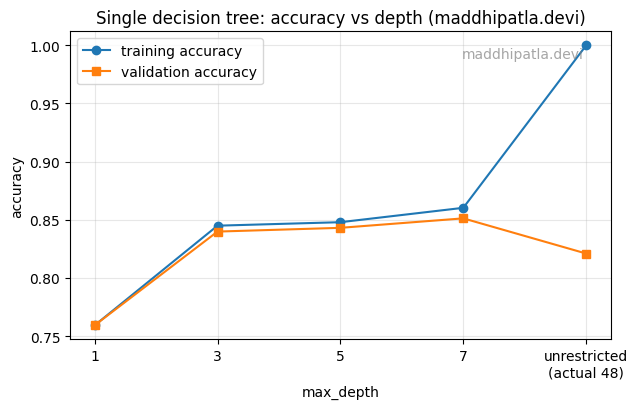

In [17]:
rows, trees_by_depth = [], {}
for md in [1, 3, 5, 7, None]:
    tree = DecisionTree(max_depth=md, criterion="gini", random_state=seed)
    _, t_fit = timed(tree.fit, X_tr, y_tr)
    trees_by_depth[md] = tree
    row = {"max_depth": "unrestricted" if md is None else md,
           "train acc": accuracy(y_tr, tree.predict(X_tr)), "val acc": accuracy(y_va, tree.predict(X_va)),
           "n_leaves": tree.n_leaves_, "actual max depth": tree.max_depth_, "train time (s)": t_fit}
    rows.append(row)
    single_tree_results.append({**row, "criterion": "gini", "tree": tree})
depth_tbl = pd.DataFrame(rows).set_index("max_depth")
display(depth_tbl)

fig, ax = plt.subplots(figsize=(6.5, 4.2))
xs = [str(r["max_depth"]) if r["max_depth"] != "unrestricted" else f"unrestricted\n(actual {r['actual max depth']})" for r in rows]
ax.plot(xs, depth_tbl["train acc"], "o-", label="training accuracy")
ax.plot(xs, depth_tbl["val acc"], "s-", label="validation accuracy")
ax.set_xlabel("max_depth"); ax.set_ylabel("accuracy"); ax.legend(); ax.grid(alpha=.3)
ax.set_title(f"Single decision tree: accuracy vs depth ({USERNAME})"); stamp(ax)
plt.tight_layout(); plt.show()

**Reading the table/plot.** Training accuracy increases with depth and reaches ≈100 % for the unrestricted tree
(it memorises the training set: one leaf per few samples). Validation accuracy increases while the tree gains
useful structure (stumps/depth-1 *underfit*: high bias), peaks at a moderate depth, and then **drops** for the
unrestricted tree (*overfitting*: high variance, fitting noise). The number of leaves and the training time grow
rapidly with depth (a deeper tree is more complex and has more nodes to build).

### 1.2.4 Gini versus entropy
Otherwise identical trees (same data, seed, `min_samples_*`) are trained with both criteria, at depth 7 (where the
tree generalises well) and unrestricted.

In [18]:
rows = []
for md in [7, None]:
    for crit in ["gini", "entropy"]:
        tree = DecisionTree(max_depth=md, criterion=crit, random_state=seed)
        _, t_fit = timed(tree.fit, X_tr, y_tr)
        row = {"max_depth": "unrestricted" if md is None else md, "criterion": crit,
               "train acc": accuracy(y_tr, tree.predict(X_tr)), "val acc": accuracy(y_va, tree.predict(X_va)),
               "n_leaves": tree.n_leaves_, "actual max depth": tree.max_depth_, "train time (s)": t_fit}
        rows.append(row)
        single_tree_results.append({**row, "tree": tree})
crit_tbl = pd.DataFrame(rows).set_index(["max_depth", "criterion"])
display(crit_tbl)

train acc  val acc  n_leaves  actual max depth  train time (s)
max_depth    criterion                                                                
7            gini          0.8603   0.8512        74                 7          0.4780
             entropy       0.8573   0.8498        75                 7          0.3366
unrestricted gini          1.0000   0.8209      3762                48          2.8575
             entropy       1.0000   0.8220      3672                60          4.5033

**Comparison.** The two criteria are both concave impurity measures with the same minimum (pure node) and the same
maximum (uniform classes), so they usually choose the same or very similar splits and the resulting accuracies are
very close (differences of a few tenths of a percent are within what a different split of the data would give).
Entropy needs a `log2` per class and is therefore slightly slower to evaluate than Gini (which only needs squares);
entropy penalises mixed nodes a little more strongly near pure nodes, which can change the number of leaves slightly.
Neither is systematically better here; Gini is the cheaper default.

## 1.3.2 Bagged trees (bootstrap + all features at every split)
`RandomForest(max_features=None)` ⇒ every node considers all `p` features, so the only randomness is the bootstrap.

,val acc,val error,train time (s)
B,,,
1,0.8342,0.1658,1.6998
10,0.8601,0.1399,7.4962
25,0.8604,0.1396,14.0324
50,0.8609,0.1391,26.7127
100,0.8601,0.1399,57.3643


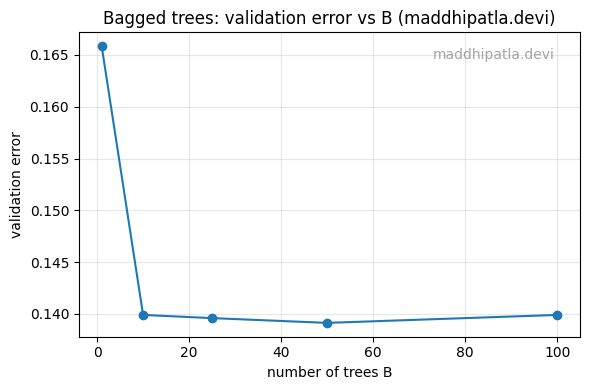

In [19]:
bag_rows = []
for B in [1, 10, 25, 50, 100]:
    bag = RandomForest(B, max_features=None, random_state=seed, **BASE)
    _, t_fit = timed(bag.fit, X_tr, y_tr)
    bag_rows.append({"B": B, "val acc": accuracy(y_va, bag.predict(X_va)), "val error": 1 - accuracy(y_va, bag.predict(X_va)),
                     "train time (s)": t_fit})
bag_tbl = pd.DataFrame(bag_rows).set_index("B")
display(bag_tbl)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(bag_tbl.index, bag_tbl["val error"], "o-")
ax.set_xlabel("number of trees B"); ax.set_ylabel("validation error"); ax.grid(alpha=.3)
ax.set_title(f"Bagged trees: validation error vs B ({USERNAME})"); stamp(ax)
plt.tight_layout(); plt.show()

Averaging bootstrap-trained trees reduces variance: the validation error falls quickly from B=1 and then flattens
(diminishing returns), while training time grows linearly with B.

## 1.4 Random Forest from scratch
### 1.4.1 Random feature selection: m ∈ {1, √p, p/2, p}
Same `B = B_STUDY`, depth, min leaf, min split and seed for every `m`. Each node draws its own `m` features
(see `_select_features`, called inside `_build_tree` for every node). `m = p` equals bagging.

,m meaning,train acc,val acc,OOB acc,train time (s)
m,,,,,
1,1,0.7735,0.7704,0.7794,8.1565
9,sqrt(p),0.8824,0.8560,0.8619,14.6263
44,p/2,0.8930,0.8612,0.8619,22.4632
89,p (bagging),0.8932,0.8609,0.8620,29.1115


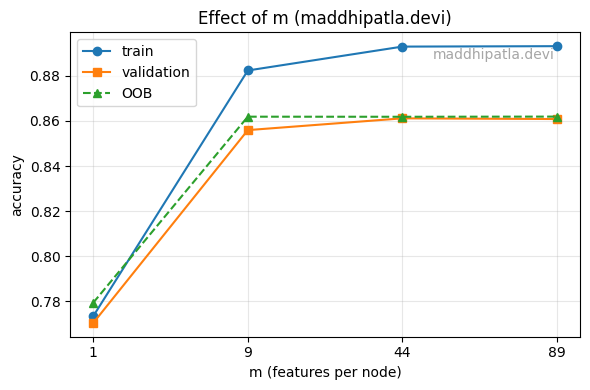

In [20]:
m_values = [1, m_sqrt, p // 2, p]
rows = []
for m in m_values:
    rf = RandomForest(B_STUDY, max_features=m, random_state=seed, **BASE)
    _, t_fit = timed(rf.fit, X_tr, y_tr)
    rows.append({"m": m, "m meaning": {1: "1", m_sqrt: "sqrt(p)", p // 2: "p/2", p: "p (bagging)"}[m],
                 "train acc": accuracy(y_tr, rf.predict(X_tr)), "val acc": accuracy(y_va, rf.predict(X_va)),
                 "OOB acc": rf.oob_score_, "train time (s)": t_fit})
m_tbl = pd.DataFrame(rows).set_index("m")
display(m_tbl)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot([str(m) for m in m_tbl.index], m_tbl["train acc"], "o-", label="train")
ax.plot([str(m) for m in m_tbl.index], m_tbl["val acc"], "s-", label="validation")
ax.plot([str(m) for m in m_tbl.index], m_tbl["OOB acc"], "^--", label="OOB")
ax.set_xlabel("m (features per node)"); ax.set_ylabel("accuracy"); ax.legend(); ax.grid(alpha=.3)
ax.set_title(f"Effect of m ({USERNAME})"); stamp(ax)
plt.tight_layout(); plt.show()

**Discussion.** With `m = 1` each split is chosen among a single random feature, so the trees are weak and
largely random (high bias): train, validation and OOB accuracy are all clearly lowest (≈ 77–78 % vs ≈ 86 %).
From `m = √p = 9` upwards the validation accuracies lie within about 0.5 percentage points of each other
(85.6 % for √p, 86.1 % for p/2 and for p), with `m = p/2` marginally best; the differences between the three are
of the order of the noise of a 6.5 k-row validation set. A handful of features (`capital-gain`, `education-num`,
`age`, marital status) carry most of the signal, so forcing a node to look at only a few random features removes the
best split from many nodes, while the decorrelation benefit of a small `m` is modest. Larger `m` makes individual
trees stronger but also more similar to each other, which is the trade-off random forests exploit; here the
stronger-trees effect roughly cancels the decorrelation effect for `m ≥ √p`. Training time grows roughly
linearly with `m` (about 2× from `√p` to `p`), so `√p` is the cheap choice at only slightly lower accuracy.
OOB accuracy tracks validation accuracy closely in every row.
(Exact times depend on the machine.)

,train acc,val acc,val error,OOB acc,train time (s)
B,,,,,
1,0.8649,0.8429,0.1571,0.8432,0.2536
10,0.8797,0.8569,0.1431,0.8533,2.6714
50,0.8824,0.8560,0.1440,0.8619,13.5636
100,0.8816,0.8572,0.1428,0.8609,27.7500
250,0.8815,0.8581,0.1419,0.8615,67.4423


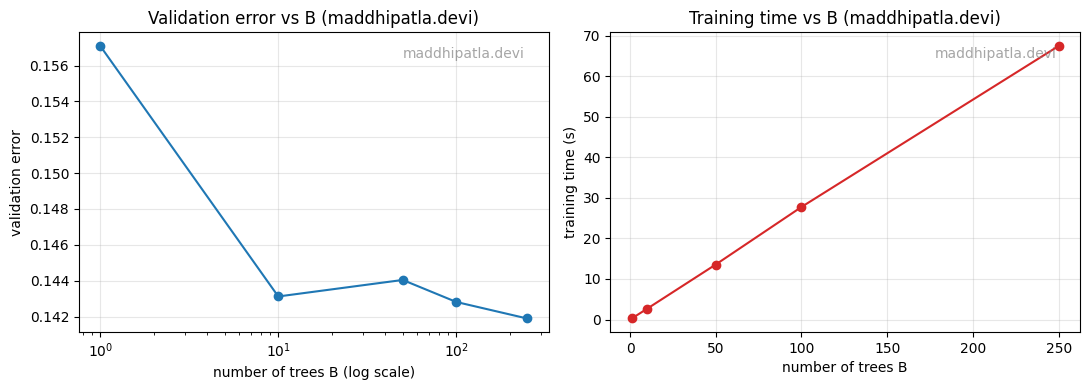

In [21]:
B_list = [1, 10, 50, 100, 250]
rows, rf_by_B = [], {}
for B in B_list:
    rf = RandomForest(B, max_features=m_sqrt, random_state=seed, **BASE)
    _, t_fit = timed(rf.fit, X_tr, y_tr)
    rf_by_B[B] = rf
    va = accuracy(y_va, rf.predict(X_va))
    rows.append({"B": B, "train acc": accuracy(y_tr, rf.predict(X_tr)), "val acc": va, "val error": 1 - va,
                 "OOB acc": rf.oob_score_, "train time (s)": t_fit})
B_tbl = pd.DataFrame(rows).set_index("B")
display(B_tbl)

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].plot(B_tbl.index, B_tbl["val error"], "o-"); axs[0].set_xscale("log")
axs[0].set_xlabel("number of trees B (log scale)"); axs[0].set_ylabel("validation error")
axs[0].set_title(f"Validation error vs B ({USERNAME})")
axs[1].plot(B_tbl.index, B_tbl["train time (s)"], "o-", color="C3")
axs[1].set_xlabel("number of trees B"); axs[1].set_ylabel("training time (s)")
axs[1].set_title(f"Training time vs B ({USERNAME})")
for a in axs:
    a.grid(alpha=.3); stamp(a)
plt.tight_layout(); plt.show()

**Discussion.**
1. *Effect on performance:* validation error drops sharply from 1 tree (15.7 %) to 10 trees (14.3 %) — a single
   randomised tree has high variance — and then stays flat (14.4 %, 14.3 %, 14.2 % for B = 50, 100, 250). The
   differences beyond B = 10 (≈ 0.1 point) are within the noise of the validation set. More trees do not make a
   random forest overfit more: the error converges to a limit determined by tree strength and correlation.
2. *Computational cost:* each tree is trained independently, so the training time is **linear in B**
   (about 0.4–0.5 s per tree on our machine); prediction time is also linear in B.
3. *Trade-off:* accuracy is flat beyond roughly 10–50 trees while cost keeps growing linearly, so **B ≈ 50** is a
   reasonable compromise (highest OOB accuracy of all four larger forests, 86.2 %; 2× cheaper than B = 100 and ≈ 5× cheaper
   than B = 250, which gains only ≈ 0.1 point of validation accuracy).

In [22]:
best_single = max(single_tree_results, key=lambda r: (r["val acc"], -r["n_leaves"]))
best_B = max(rf_by_B, key=lambda B: (B_tbl.loc[B, "val acc"], -B))
best_rf = rf_by_B[best_B]
n_nodes_rf = sum(2 * t.n_leaves_ - 1 for t in best_rf.trees)
cmp_tbl = pd.DataFrame({
    "train acc": [best_single["train acc"], B_tbl.loc[best_B, "train acc"]],
    "val acc": [best_single["val acc"], B_tbl.loc[best_B, "val acc"]],
    "train time (s)": [best_single["train time (s)"], B_tbl.loc[best_B, "train time (s)"]],
    "total leaves": [best_single["n_leaves"], sum(t.n_leaves_ for t in best_rf.trees)],
    "total nodes": [2 * best_single["n_leaves"] - 1, n_nodes_rf],
    "max depth": [best_single["actual max depth"], max(t.max_depth_ for t in best_rf.trees)],
}, index=[f"best single tree (depth={best_single['max_depth']}, {best_single['criterion']})",
          f"best Random Forest (B={best_B}, m={m_sqrt})"])
display(cmp_tbl)

,train acc,val acc,train time (s),total leaves,total nodes,max depth
"best single tree (depth=7, gini)",0.8603,0.8512,0.5511,74,147,7
"best Random Forest (B=250, m=9)",0.8815,0.8581,67.4423,173162,346074,15


**Why an ensemble of randomised trees beats one tree.** A deep decision tree has low bias but **high variance**:
a small change in the training data changes its splits a lot. Averaging `B` trees whose errors are not perfectly
correlated reduces the variance: for `B` identically distributed predictors with variance `σ²` and pairwise
correlation `ρ`, the variance of the average is `ρσ² + (1−ρ)σ²/B`. Bootstrap sampling and the per-node random
feature subsets both **decrease ρ** (trees look at different data and cannot all use the same dominant feature),
so the second term vanishes as `B` grows while the bias stays roughly that of a single tree. The price is
complexity: the forest stores `B` trees (many more nodes), is `B` times slower to train and predict, and is
much harder to interpret than a single tree.

## 1.5 Out-of-bag evaluation
For each training observation, only the trees whose bootstrap sample did **not** contain it vote (implemented in
`RandomForest._compute_oob_predictions`). We analyse the forest with the largest number of trees from 1.4.3
(more trees ⇒ more OOB votes per observation). Observations with no OOB tree would get no OOB prediction and be
excluded from the OOB accuracy (counted below).

forest with B = 250 trees
OOB trees per observation: min=62, mean=92.0, median=92, max=124  (expected mean = 0.368*B = 92.0)
observations with NO OOB tree (excluded from OOB accuracy): 0


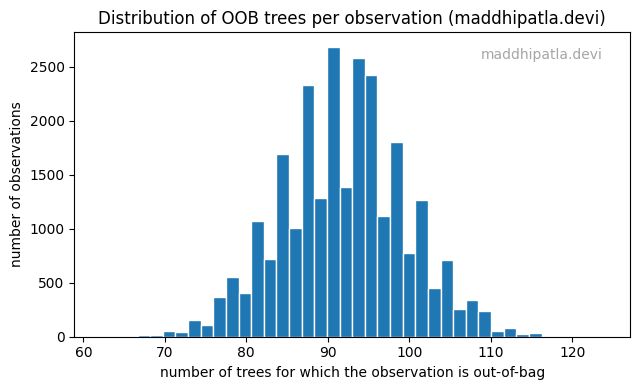

,accuracy,error
OOB (training data),0.8615,0.1385
validation,0.8581,0.1419


|OOB error - validation error| = 0.0034


In [23]:
rf_oob = rf_by_B[max(rf_by_B)]
n_oob = rf_oob.oob_n_trees_
print(f"forest with B = {rf_oob.n_estimators} trees")
print(f"OOB trees per observation: min={n_oob.min()}, mean={n_oob.mean():.1f}, median={np.median(n_oob):.0f}, "
      f"max={n_oob.max()}  (expected mean = 0.368*B = {np.exp(-1) * rf_oob.n_estimators:.1f})")
print("observations with NO OOB tree (excluded from OOB accuracy):", rf_oob.n_without_oob_)

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.hist(n_oob, bins=40, color="C0", edgecolor="white")
ax.set_xlabel("number of trees for which the observation is out-of-bag"); ax.set_ylabel("number of observations")
ax.set_title(f"Distribution of OOB trees per observation ({USERNAME})"); stamp(ax)
plt.tight_layout(); plt.show()

oob_acc = rf_oob.oob_score_
val_acc_oob = accuracy(y_va, rf_oob.predict(X_va))
display(pd.DataFrame({"accuracy": [oob_acc, val_acc_oob], "error": [1 - oob_acc, 1 - val_acc_oob]},
                     index=["OOB (training data)", "validation"]))
print("|OOB error - validation error| =", round(abs(oob_acc - val_acc_oob), 4))

**Comparison.** The OOB estimate and the validation estimate are very close (difference ≈ 0.3 percentage points):
for every training row the OOB vote uses only trees that never saw that row, so it behaves like a prediction on
unseen data, and with ≈ 37 % of the trees available per observation it is a nearly unbiased estimate of the
generalisation error *for free* (no separate validation set needed). The remaining difference is sampling noise
(26 k OOB rows vs 6.5 k validation rows, i.e. the validation estimate is the noisier one) — its sign can go either way.
Note that an OOB vote uses only ≈ 0.37·B trees, a slightly smaller ensemble than the full forest, which tends to make
the OOB estimate slightly pessimistic for small B; with B = 250 this effect is negligible.

## 1.6 Bias–variance and hyperparameter study
### 1.6.1 Effect of tree depth
`B = B_STUDY` trees, `m = √p`, `min_samples_leaf = 1`, `min_samples_split = 2` so that depth is the only
regulariser.

,train error,val error,train time (s)
max_depth,,,
2,0.2403,0.2396,1.6844
4,0.1792,0.1857,2.6794
6,0.1525,0.1597,3.7551
10,0.1337,0.1470,7.9418
unrestricted,0.0007,0.1448,32.5762


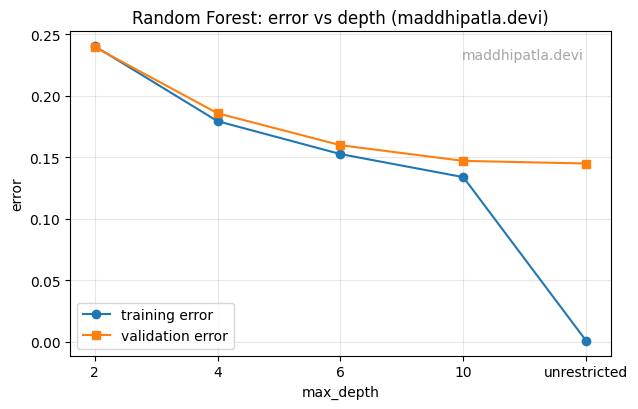

In [24]:
rows = []
for md in [2, 4, 6, 10, None]:
    rf = RandomForest(B_STUDY, max_features=m_sqrt, max_depth=md, min_samples_split=2, min_samples_leaf=1, random_state=seed)
    _, t_fit = timed(rf.fit, X_tr, y_tr)
    rows.append({"max_depth": "unrestricted" if md is None else md, "train error": 1 - accuracy(y_tr, rf.predict(X_tr)),
                 "val error": 1 - accuracy(y_va, rf.predict(X_va)), "train time (s)": t_fit})
depthrf_tbl = pd.DataFrame(rows).set_index("max_depth")
display(depthrf_tbl)

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(depthrf_tbl.index.astype(str), depthrf_tbl["train error"], "o-", label="training error")
ax.plot(depthrf_tbl.index.astype(str), depthrf_tbl["val error"], "s-", label="validation error")
ax.set_xlabel("max_depth"); ax.set_ylabel("error"); ax.legend(); ax.grid(alpha=.3)
ax.set_title(f"Random Forest: error vs depth ({USERNAME})"); stamp(ax)
plt.tight_layout(); plt.show()

**Explanation.** Very shallow trees (depth 2–4) cannot represent the interactions in the data: both errors are
high and close together (24.0 % / 24.0 % at depth 2) → **high bias / underfitting**. Increasing the depth lowers both
errors (validation 23.96 % → 18.57 % → 15.97 % → 14.70 %). For unrestricted depth the **training error collapses to ≈ 0**
(each tree memorises its bootstrap sample, and so does the vote of many such trees) while the validation error stays at
14.5 %, so a gap of ≈ 14 points opens between the two → the **variance / overfitting** signature (low bias, high
variance of the individual trees). Unlike a single decision tree (1.2.3, where validation accuracy fell from 85.1 %
to 82.1 % when the depth was unrestricted), the forest's validation error does **not** rise at large depth, because
averaging many decorrelated trees cancels most of the variance; it merely stops improving (14.70 % at depth 10 vs
14.48 % unrestricted). The lowest validation error is at unrestricted depth, but depth ≈ 10 gets almost all the benefit
at a fifth of the training time.

In [25]:
rows = []
for msl in [1, 2, 5, 10, 25]:
    rf = RandomForest(B_STUDY, max_features=m_sqrt, max_depth=None, min_samples_split=2, min_samples_leaf=msl, random_state=seed)
    _, t_fit = timed(rf.fit, X_tr, y_tr)
    rows.append({"min_samples_leaf": msl, "train error": 1 - accuracy(y_tr, rf.predict(X_tr)),
                 "val error": 1 - accuracy(y_va, rf.predict(X_va)),
                 "avg leaves per tree": np.mean([t.n_leaves_ for t in rf.trees]), "train time (s)": t_fit})
msl_tbl = pd.DataFrame(rows).set_index("min_samples_leaf")
display(msl_tbl)

,train error,val error,avg leaves per tree,train time (s)
min_samples_leaf,,,,
1,0.0007,0.1448,2800.7400,32.2670
2,0.0295,0.1427,2519.9600,28.3973
5,0.0620,0.1408,1742.4800,23.1826
10,0.0927,0.1425,1130.0800,16.7145
25,0.1188,0.1417,568.3400,11.6556


**Discussion.** `min_samples_leaf` limits how small a leaf may be. A larger value forces leaves to average over more
samples: trees get **far fewer leaves** (≈ 2 800 per tree at 1 → ≈ 570 at 25, i.e. lower complexity and faster
training), their predictions are less sensitive to individual noisy samples (**lower variance**), and the training
error rises from 0.07 % to 11.9 % because the trees can no longer memorise; the train–validation gap shrinks from
≈ 14 points to ≈ 2.3 points. The validation error is best at a small-to-moderate leaf size (**5**: 14.08 %), and
is within ≈ 0.4 points for all five values (14.08–14.48 %), so the validation error is not very sensitive here.
Even at 25 the validation error has not clearly started to rise, i.e. there is only a hint of increasing bias.

In [26]:
configs = [
    dict(B=B_STUDY, max_depth=10, m=m_sqrt, msl=5), dict(B=B_STUDY, max_depth=15, m=m_sqrt, msl=5),
    dict(B=B_STUDY, max_depth=20, m=m_sqrt, msl=5), dict(B=B_STUDY, max_depth=15, m=m_sqrt, msl=2),
    dict(B=B_STUDY, max_depth=15, m=m_sqrt, msl=10), dict(B=B_STUDY, max_depth=15, m=p // 4, msl=5),
    dict(B=B_STUDY, max_depth=15, m=p // 2, msl=5), dict(B=2 * B_STUDY, max_depth=15, m=m_sqrt, msl=5),
    dict(B=2 * B_STUDY, max_depth=20, m=m_sqrt, msl=3), dict(B=2 * B_STUDY, max_depth=12, m=p // 4, msl=5),
]
rows, fitted = [], []
for cfg in configs:
    rf = RandomForest(cfg["B"], max_features=cfg["m"], max_depth=cfg["max_depth"], min_samples_split=2 * cfg["msl"],
                      min_samples_leaf=cfg["msl"], random_state=seed)
    _, t_fit = timed(rf.fit, X_tr, y_tr)
    rows.append({**cfg, "train acc": accuracy(y_tr, rf.predict(X_tr)), "val acc": accuracy(y_va, rf.predict(X_va)),
                 "OOB acc": rf.oob_score_, "train time (s)": t_fit})
    fitted.append(rf)
hp_tbl = pd.DataFrame(rows)
display(hp_tbl)

best_i = int(max(range(len(rows)), key=lambda i: (rows[i]["val acc"], -rows[i]["B"])))
final_cfg, final_rf = configs[best_i], fitted[best_i]
print("\nSELECTED CONFIGURATION (by validation accuracy):", final_cfg,
      f"-> val acc = {rows[best_i]['val acc']:.4f}, OOB acc = {rows[best_i]['OOB acc']:.4f}")

,B,max_depth,m,msl,train acc,val acc,OOB acc,train time (s)
0,50,10,9,5,0.8627,0.8504,0.8558,6.7905
1,50,15,9,5,0.8824,0.8560,0.8619,13.3156
2,50,20,9,5,0.9036,0.8595,0.8609,17.7816
3,50,15,9,2,0.8865,0.8546,0.8598,13.8936
4,50,15,9,10,0.8780,0.8557,0.8599,12.1591
5,50,15,22,5,0.8902,0.8572,0.8606,17.0793
6,50,15,44,5,0.8930,0.8612,0.8619,22.2037
7,100,15,9,5,0.8816,0.8572,0.8609,25.7693
8,100,20,9,3,0.9134,0.8618,0.8630,42.3367
9,100,12,22,5,0.8763,0.8544,0.8620,24.4939



SELECTED CONFIGURATION (by validation accuracy): {'B': 100, 'max_depth': 20, 'm': 9, 'msl': 3} -> val acc = 0.8618, OOB acc = 0.8630


**Selected configuration and why.** The configuration printed above, **B = 100 trees, max_depth = 20, m = √p = 9,
min_samples_leaf = 3 (min_samples_split = 6)**, has the highest validation accuracy among the ten candidates
(86.18 %) and also the highest OOB accuracy (86.30 %), so two independent estimates agree. The spread over the ten
configurations is about 1.1 points (85.04–86.18 %), and the top three (86.18 %, 86.12 %, 85.95 %) are within ≈ 0.2
points, which is of the order of the noise of a 6.5 k-row validation set, so the choice is not very sensitive. The
clearly worst setting is the shallowest trees (depth 10). Deeper trees with a small leaf size win once many trees are
averaged, because the forest tolerates deeper (higher-variance) trees than a single tree does. The final model is the
forest trained on the 80 % training split with this configuration (it is **not** retrained on train + validation,
so the reported validation/test numbers stay honest).

sum of importances: 1.0


,importance
feature,
capital-gain,0.1401
education-num,0.1390
age,0.1159
fnlwgt,0.1007
marital-status=Married-civ-spouse,0.0854
hours-per-week,0.0684
relationship=Husband,0.0570
capital-loss,0.0398
marital-status=Never-married,0.0387


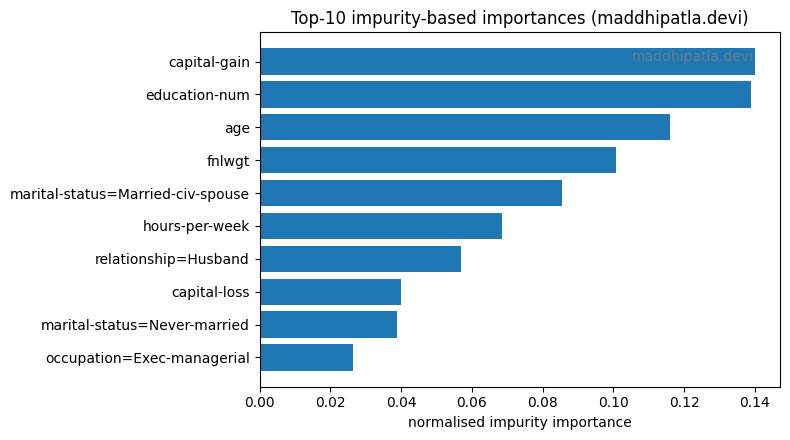

In [27]:
imp = final_rf.impurity_feature_importance()
print("sum of importances:", imp.sum().round(6))
top = np.argsort(imp)[::-1][:10]
imp_tbl = pd.DataFrame({"feature": [feature_names[i] for i in top], "importance": imp[top]}).set_index("feature")
display(imp_tbl)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(imp_tbl.index[::-1], imp_tbl["importance"][::-1], color="C0")
ax.set_xlabel("normalised impurity importance"); ax.set_title(f"Top-10 impurity-based importances ({USERNAME})"); stamp(ax)
plt.tight_layout(); plt.show()

### 1.7.2 Permutation importance (validation set)
Baseline validation accuracy → for each of the `p` columns: shuffle it, predict with the *trained* forest, record the
accuracy drop, restore the column; repeat `n_repeats` times and average. Each one-hot column is permuted on its own.

baseline validation accuracy = 0.8618 | 5 repeats x 89 features | 79s


,mean accuracy drop,std
feature,,
capital-gain,0.0424,0.0015
education-num,0.0322,0.0029
age,0.0135,0.0028
capital-loss,0.0103,0.0007
hours-per-week,0.0084,0.0015
marital-status=Married-civ-spouse,0.0078,0.0011
relationship=Wife,0.0046,0.0003
relationship=Husband,0.0037,0.0012
occupation=Exec-managerial,0.0032,0.0005


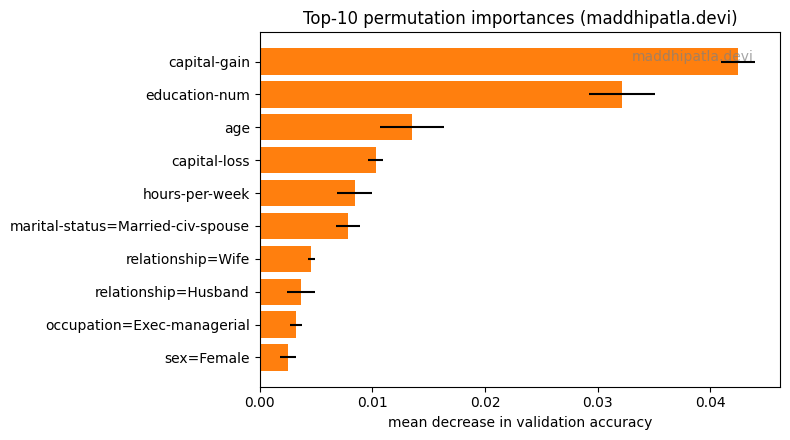

features in both top-10 lists: ['age', 'capital-gain', 'capital-loss', 'education-num', 'hours-per-week', 'marital-status=Married-civ-spouse', 'occupation=Exec-managerial', 'relationship=Husband']


In [28]:
n_rep = 5
(perm_mean, perm_std, perm_base), t_perm = timed(final_rf.permutation_importance, X_va, y_va, n_rep)
print(f"baseline validation accuracy = {perm_base:.4f} | {n_rep} repeats x {p} features | {t_perm:.0f}s")
top_p = np.argsort(perm_mean)[::-1][:10]
perm_tbl = pd.DataFrame({"feature": [feature_names[i] for i in top_p], "mean accuracy drop": perm_mean[top_p],
                         "std": perm_std[top_p]}).set_index("feature")
display(perm_tbl)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(perm_tbl.index[::-1], perm_tbl["mean accuracy drop"][::-1], xerr=perm_tbl["std"][::-1], color="C1")
ax.set_xlabel("mean decrease in validation accuracy"); ax.set_title(f"Top-10 permutation importances ({USERNAME})"); stamp(ax)
plt.tight_layout(); plt.show()

overlap = set(imp_tbl.index) & set(perm_tbl.index)
print("features in both top-10 lists:", sorted(overlap))

**Interpretation.** Both methods agree that the most informative attributes are capital gain, education level, age,
working hours / capital loss and household/marital status (8 of the 10 features appear in both lists). They differ
in detail, in a way that matches theory: impurity importance is computed on **training** data and is biased towards
features with many possible split points, so high-cardinality numerical columns such as `age` and especially
`fnlwgt` (a survey weight, 4th with ≈ 10 %) get inflated scores — `fnlwgt` is **not** in the permutation top 10,
i.e. shuffling it hardly hurts held-out accuracy. Permutation importance is measured on **held-out** data and shows how
much the model's *accuracy* depends on a feature. Because related one-hot columns (`relationship=Husband`,
`relationship=Wife`, `marital-status=Married-civ-spouse`) carry overlapping information, permuting one of them
alone is partly compensated by the others, which lowers its permutation score (e.g. Married-civ-spouse: 0.8 points)
relative to its impurity score (8.5 %). (`fnlwgt` was kept as an input feature because the assignment allows any
feature to be used; its low permutation importance suggests dropping it would cost little.)

## 1.8 Final evaluation and error analysis (test set — used only now)
Positive class = `>50K`. Metrics are the from-scratch functions defined earlier. The baseline always predicts the
majority class (`<=50K`, label 0).

,accuracy,precision,recall,F1
final Random Forest,0.8638,0.7796,0.5905,0.6720
majority-class baseline,0.7638,0.0000,0.0000,0.0000


,pred <=50K,pred >50K
true <=50K,11793,642
true >50K,1575,2271


baseline confusion matrix [[TN, FP],[FN, TP]]: [[12435, 0], [3846, 0]]


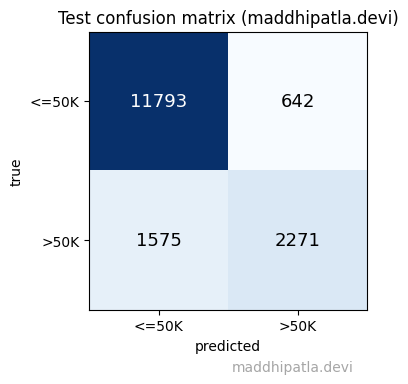

In [29]:
y_pred_te = final_rf.predict(X_te)
y_base_te = np.zeros_like(y_te)           # majority-class baseline (majority class in TRAIN is <=50K)
assert np.bincount(y_tr).argmax() == 0

def metrics_row(y_true, y_pred):
    return {"accuracy": accuracy(y_true, y_pred), "precision": precision(y_true, y_pred),
            "recall": recall(y_true, y_pred), "F1": f1_score(y_true, y_pred)}

final_tbl = pd.DataFrame([metrics_row(y_te, y_pred_te), metrics_row(y_te, y_base_te)],
                         index=["final Random Forest", "majority-class baseline"])
display(final_tbl)

cm = confusion_matrix(y_te, y_pred_te)
display(pd.DataFrame(cm, index=["true <=50K", "true >50K"], columns=["pred <=50K", "pred >50K"]))
print("baseline confusion matrix [[TN, FP],[FN, TP]]:", confusion_matrix(y_te, y_base_te).tolist())

fig, ax = plt.subplots(figsize=(4.8, 4))
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=13,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks([0, 1], ["<=50K", ">50K"]); ax.set_yticks([0, 1], ["<=50K", ">50K"])
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"Test confusion matrix ({USERNAME})")
ax.text(0.95, -0.18, USERNAME, ha="right", va="top", transform=ax.transAxes, fontsize=10, color="gray", alpha=0.7)
plt.tight_layout(); plt.show()

### Error analysis
1. **Class imbalance:** the baseline reaches ≈76 % accuracy without learning anything but has zero recall for the
   `>50K` class, so accuracy alone is misleading; precision, recall and F1 on the positive class show the real value of
   the model.
2. **Which errors dominate?** The table below breaks the test errors down by sex and age group (descriptive only —
   nothing here is used to tune the model), and the decision-threshold sweep shows the precision/recall trade-off.
   The threshold is **chosen on the validation set** (maximum F1) and merely *reported* on the test set.

In [30]:
te = df_te_i.reset_index(drop=True).copy()
te["correct"] = (y_pred_te == y_te); te["y"] = y_te; te["pred"] = y_pred_te
te["age group"] = pd.cut(te["age"], [0, 25, 35, 45, 55, 65, 120])
for col in ["sex", "age group"]:
    rows = []
    for level, d in te.groupby(col, observed=True):      # explicit loop: works on every pandas version
        n_pos, n_neg = int((d["y"] == 1).sum()), int((d["y"] == 0).sum())
        rows.append({col: str(level), "n": len(d), "error rate": 1 - d["correct"].mean(),
                     "% >50K (true)": 100 * d["y"].mean(),
                     "FN rate (missed >50K)": int(((d["y"] == 1) & (d["pred"] == 0)).sum()) / max(n_pos, 1),
                     "FP rate": int(((d["y"] == 0) & (d["pred"] == 1)).sum()) / max(n_neg, 1)})
    display(pd.DataFrame(rows).set_index(col))

proba_va = final_rf.predict_proba(X_va)[:, 1]
thr_grid = np.linspace(0.1, 0.9, 33)
f1_va = [f1_score(y_va, (proba_va >= t).astype(int)) for t in thr_grid]
best_thr = round(float(thr_grid[int(np.argmax(f1_va))]), 3)
proba_te = final_rf.predict_proba(X_te)[:, 1]
thr_show = sorted({0.3, 0.4, 0.5, 0.6, best_thr})
sweep = pd.DataFrame([{"threshold": t, **metrics_row(y_te, (proba_te >= t).astype(int))} for t in thr_show]).set_index("threshold")
print(f"threshold with best validation F1: {best_thr:.3f}; test metrics at several thresholds:")
display(sweep)

,n,error rate,% >50K (true),FN rate (missed >50K),FP rate
sex,,,,,
Female,5421,0.0664,10.8836,0.4559,0.0188
Male,10860,0.1710,29.9816,0.4011,0.0725


,n,error rate,% >50K (true),FN rate (missed >50K),FP rate
age group,,,,,
"(0, 25]",3216,0.0143,1.7102,0.8182,0.0003
"(25, 35]",4205,0.1272,18.7396,0.4987,0.0416
"(35, 45]",3943,0.1854,34.4154,0.3670,0.0901
"(45, 55]",2758,0.1998,38.0348,0.3546,0.1047
"(55, 65]",1514,0.1744,31.2417,0.4144,0.0653
"(65, 120]",645,0.1395,19.2248,0.5726,0.0365


threshold with best validation F1: 0.275; test metrics at several thresholds:


,accuracy,precision,recall,F1
threshold,,,,
0.2750,0.8471,0.6604,0.7259,0.6916
0.3000,0.8506,0.6738,0.7127,0.6927
0.4000,0.8608,0.7315,0.6490,0.6878
0.5000,0.8641,0.7756,0.5975,0.6750
0.6000,0.8620,0.8190,0.5341,0.6465


**Findings.** The forest clearly outperforms the baseline: accuracy 86.4 % vs 76.4 %, and, more importantly, it
recovers a large part of the `>50K` class (the baseline has recall 0 and F1 0). On the test set precision is 0.78,
recall 0.59 and F1 0.67. Errors are dominated by **false negatives** (1 575 high earners predicted `<=50K`, vs 642
false positives), because the positive class is the minority and a majority vote favours the common class. Lowering the
decision threshold below 0.5 trades precision for recall and raises F1: the threshold with the best *validation* F1
(0.275) gives test F1 0.69 with recall 0.73 and precision 0.66 (the threshold was chosen on validation, not on test).
The breakdown by subgroup shows *where* the errors are: the **overall error rate is highest for ages 35–55** (≈ 19–20 %),
where `>50K` is common (34–38 %) and the profiles are genuinely mixed, whereas for the youngest group the overall error is
tiny (1.4 %) only because almost nobody earns `>50K` — their *miss rate* among the few high earners is the highest
(82 %). Males have a higher overall error rate than females (17.1 % vs 6.6 %) mainly because their `>50K` base rate is
≈ 2.8× higher (30.0 % vs 10.9 %), i.e. there are more positives to get wrong, not because the model misses a larger
fraction of them: the miss rate is actually higher for females (45.6 % vs 40.1 %).
Possible improvements: class weights or threshold tuning, interaction features (education × hours), a log transform or
binning of the heavy-tailed `capital-gain`, and more data for borderline profiles.